TSA, HT-2, EF MSU, Mikhailov_Akhanov

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.tsatools import detrend

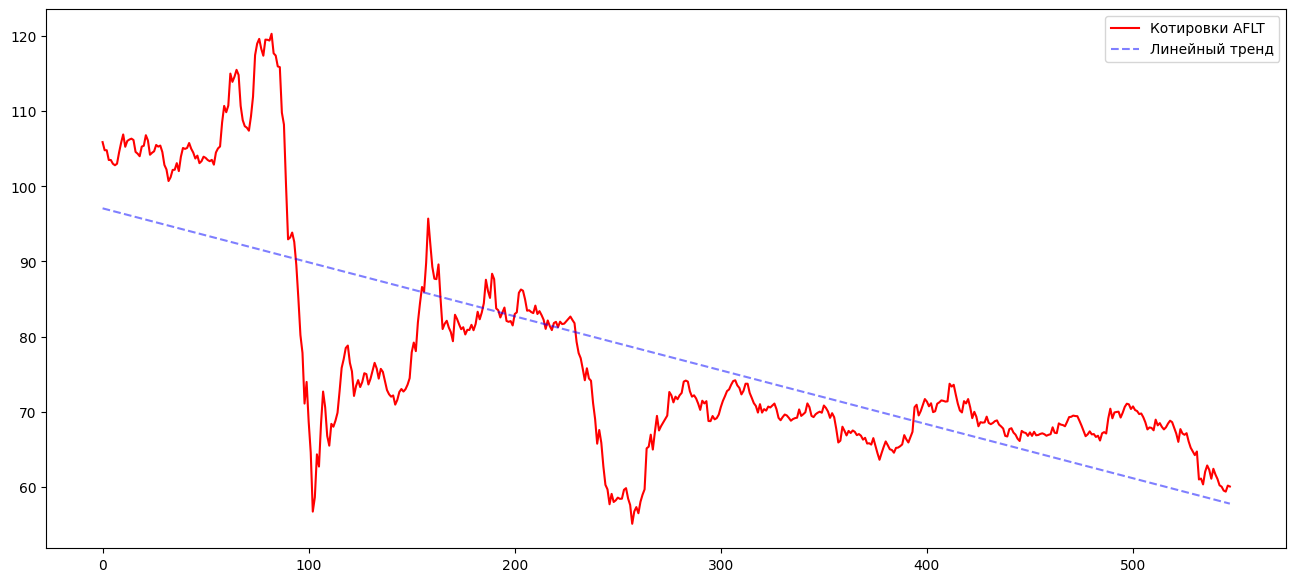

In [3]:
data_csv = pd.read_csv('Data-TS-HT-2.csv', sep=';')
open_price = data_csv['OPEN']
close_price = data_csv['CLOSE']

detrended = detrend(close_price, order=1)
trend = close_price - detrended

plt.figure(figsize=(16,7))
plt.plot(close_price, label='Котировки AFLT', color='red')
plt.plot(trend, label='Линейный тренд', color='blue', linestyle='--', alpha=0.5)
plt.legend()
plt.show()

Явно заметно, что ряд нестационарный, причем удаление тренда не поможет - приведем график без линейного тренда:

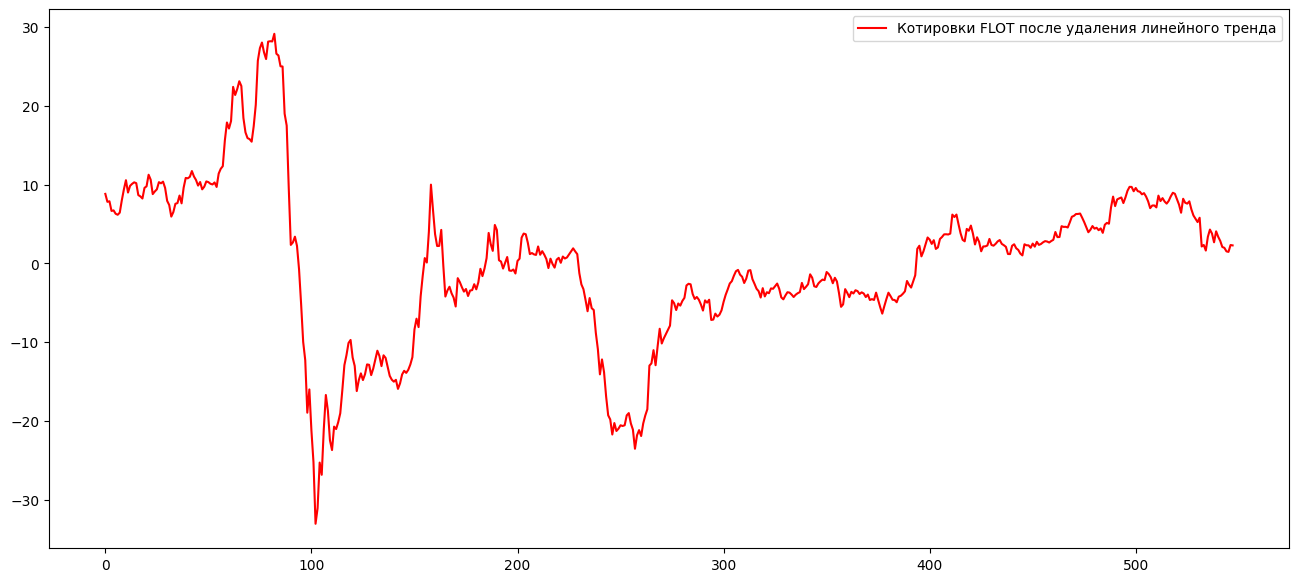

In [4]:
from statsmodels.tsa.tsatools import detrend

detrended = detrend(close_price, order=1)

plt.figure(figsize=(16,7))
plt.plot(detrended, label='Котировки FLOT после удаления линейного тренда', color='red')
plt.legend()
plt.show()

Проведем тесты Дики-Фулера и КПСС с константой и константой+трендом, чтобы проверить, стационарен ли ряд

In [5]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(close_price) # Тестируем сначала без тренда
print(f'ADF Statistic : {adf_result[0]}')
print(f'P-Value : {adf_result[1]}')
if np.abs(adf_result[4]['5%']) > np.abs(adf_result[0]):
    print('Ряд нестационарен на 5% уровне значимости для теста ДФ с константой и без тренда')
else:
    print('Ряд стационарен на 5% уровне значимости для теста ДФ с константой и без тренда')

# Теперь проведем тот же тест, но с линейным трендом
adf_result = adfuller(close_price, regression='ct') # Добавили тренд в тест
print(f'ADF Statistic : {adf_result[0]}')
print(f'P-Value : {adf_result[1]}')
if np.abs(adf_result[4]['5%']) > np.abs(adf_result[0]):
    print('Ряд нестационарен на 5% уровне знач≥имости для теста ДФ с константой и трендом')
else:
    print('Ряд стационарен на 5% уровне значимости для теста ДФ с константой и трендом')

adf_stat, pvalue, lags, store = adfuller(close_price,regression='ct', store=True)
print(store.resols.summary())

ADF Statistic : -2.1078505804307004
P-Value : 0.24136958393503327
Ряд нестационарен на 5% уровне значимости для теста ДФ с константой и без тренда
ADF Statistic : -2.8634351373481195
P-Value : 0.17462130449409657
Ряд нестационарен на 5% уровне знач≥имости для теста ДФ с константой и трендом
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.105
Method:                 Least Squares   F-statistic:                     4.452
Date:                Thu, 25 Dec 2025   Prob (F-statistic):           5.00e-09
Time:                        22:15:38   Log-Likelihood:                -945.17
No. Observations:                 531   AIC:                             1928.
Df Residuals:                     512   BIC:                             2010.
Df Model:                          18                                       

Собственно, если даже тест Дики-Фулера показывает нестационарность в обоих случаях, то КПСС точно укажет на нестационарность (по причине большей мощности оного), покажем формально:

In [6]:
from statsmodels.tsa.stattools import kpss

kpss_result = kpss(close_price, regression='c') # Проверим вначале без тренда
print(f'KPSS Statistic : {kpss_result[0]}')
print(f'P-Value : {kpss_result[1]}')
if np.abs(kpss_result[0]) < np.abs(kpss_result[3]['5%']):
    print('Ряд стационарен на 5% уровне значимости для теста KPSS с константой и без тренда')
else:
    print('Ряд нестационарен на 5% уровне значимости для теста KPSS с константой и без тренда')

# Для случая с трендом
kpss_result = kpss(close_price, regression='ct')
print(f'KPSS Statistic : {kpss_result[0]}')
print(f'P-Value : {kpss_result[1]}')
if np.abs(kpss_result[0]) < np.abs(kpss_result[3]['5%']):
    print('Ряд тренд-стационарен на 5% уровне значимости для теста KPSS с константой и трендом')
else:
    print('Ряд нестационарен на 5% уровне значимости для теста KPSS с константой и трендом')

KPSS Statistic : 2.1607693682966693
P-Value : 0.01
Ряд нестационарен на 5% уровне значимости для теста KPSS с константой и без тренда
KPSS Statistic : 0.3584497165865796
P-Value : 0.01
Ряд нестационарен на 5% уровне значимости для теста KPSS с константой и трендом


C:\Users\tempadmin\AppData\Local\Temp\ipykernel_16868\1609338182.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(close_price, regression='c') # Проверим вначале без тренда
C:\Users\tempadmin\AppData\Local\Temp\ipykernel_16868\1609338182.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(close_price, regression='ct')


Что и требовалось доказать. Построим теперь графики ACF и PACF - начнем с ACF:

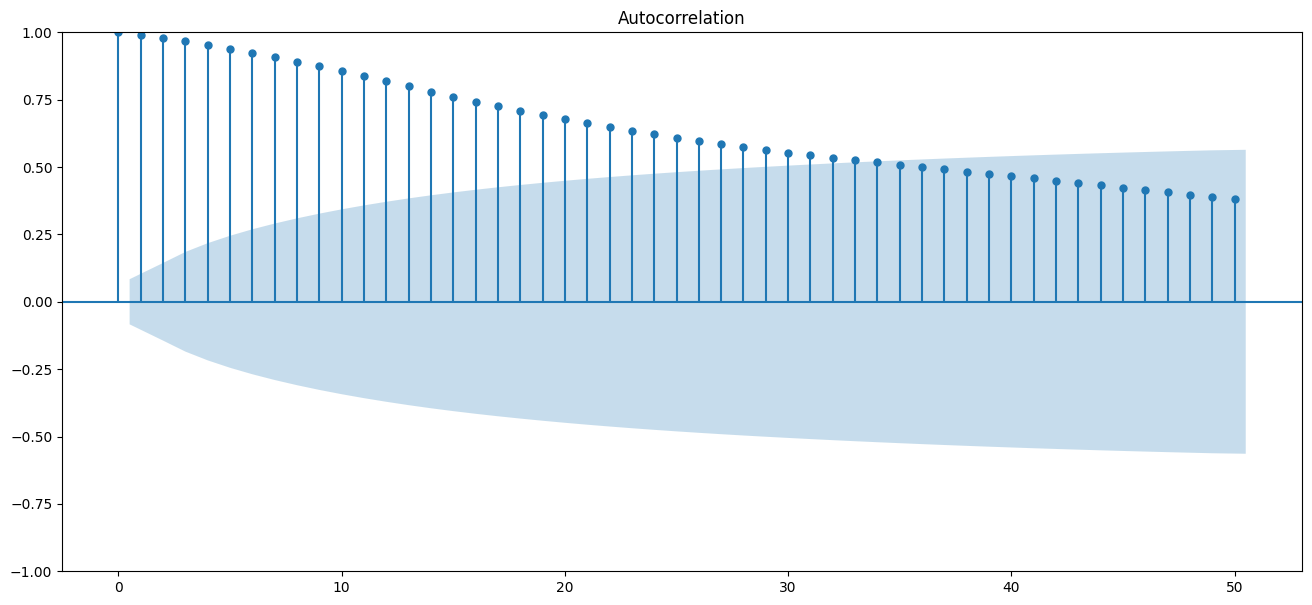

In [7]:
# ACF first
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(16,7))
plot_acf(close_price, lags=50,ax=ax)
plt.show()

Как видим, ACF очень медленно сходится к 0 (причем величина коффициента корреляции первого порядка почти 1, что свидетельствует в пользу нестационарности), что характерно для моделей AR, но слишком медленное затухание (почти вечное влияние) говорит о нестационарности. Построим теперь PACF

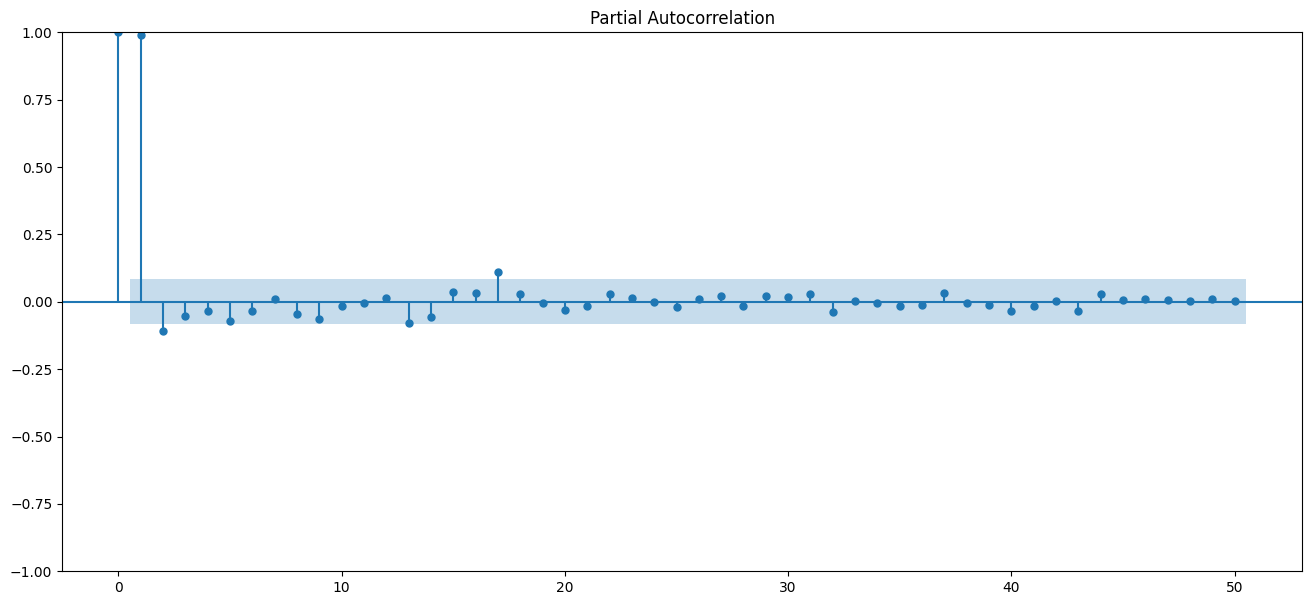

In [8]:
from statsmodels.graphics.tsaplots import plot_pacf

fig, ax = plt.subplots(figsize=(16,7))
plot_pacf(close_price, lags=50,ax=ax)
plt.show()

Получившаяся функция PACF вовсе не соответствует той модели AR, которую можно было бы ожидать увидеть исходя из графика выше, все это говорит о нестационарности данного ВР

Теперь проделаем все то же самое, но уже для ряда доходностей, который будет рассчитываться как разница между дневной ценой открытия и ценой закрытия

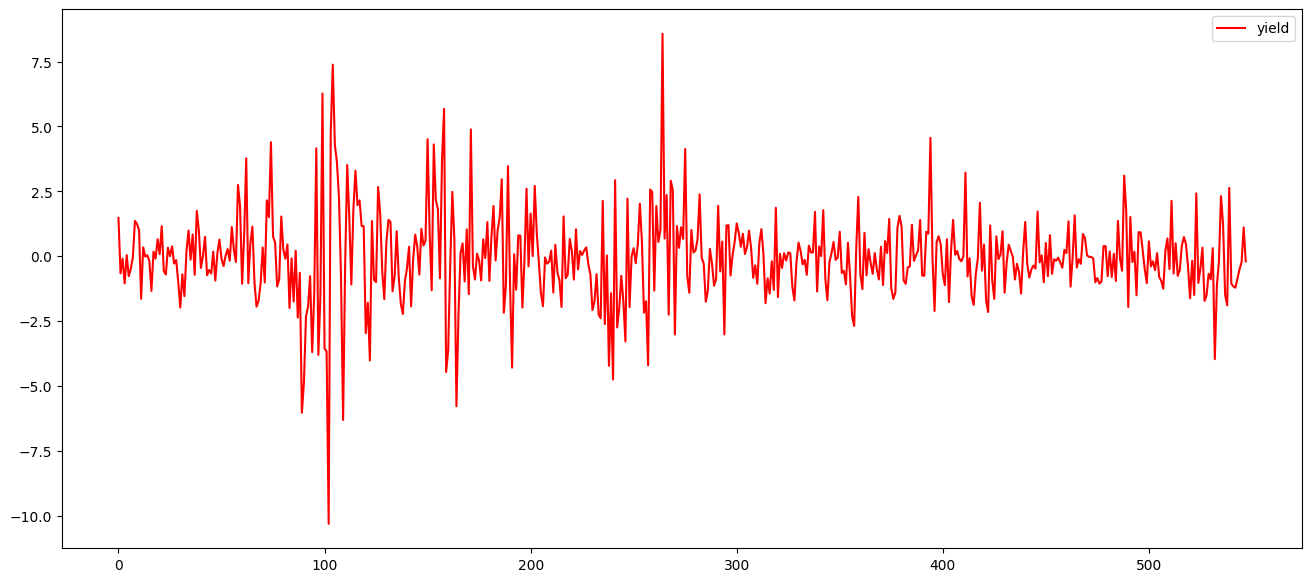

In [9]:
yld = (close_price - open_price)/open_price * 100
plt.figure(figsize=(16,7))
plt.plot(yld, label='yield', color='red')
plt.legend()
plt.show()

Ряд доходностей, в свою очередь, уже явно стационарен - проверим это формально при помощи тестов - сначала ДФ:

In [10]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(yld) # Тестируем сначала без тренда
print(f'ADF Statistic : {adf_result[0]}')
p = adf_result[1]
if p == 0.0:
    print("P-Value < 1e-16")
else:
    print(f"P-Value : {p:.3e}")
print(f'P-Value : {adf_result[1]}')
if np.abs(adf_result[4]['5%']) > np.abs(adf_result[0]):
    print('Ряд нестационарен на 5% уровне значимости для теста ДФ с константой и без тренда')
else:
    print('Ряд стационарен на 5% уровне значимости для теста ДФ с константой и без тренда')

# Теперь проведем тот же тест, но с линейным трендом
adf_result = adfuller(yld, regression='ct') # Добавили тренд в тест
print(f'ADF Statistic : {adf_result[0]}')
print(f'P-Value : {adf_result[1]:.3e}')
if np.abs(adf_result[4]['5%']) > np.abs(adf_result[0]):
    print('Ряд нестационарен на 5% уровне значимости для теста ДФ с константой и трендом')
else:
    print('Ряд стационарен на 5% уровне значимости для теста ДФ с константой и трендом')

adf_stat, pvalue, lags, store = adfuller(yld,regression='ct', store=True)
print(store.resols.summary())

ADF Statistic : -20.942284292921904
P-Value < 1e-16
P-Value : 0.0
Ряд стационарен на 5% уровне значимости для теста ДФ с константой и без тренда
ADF Statistic : -20.934544819730906
P-Value : 0.000e+00
Ряд стационарен на 5% уровне значимости для теста ДФ с константой и трендом
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.446
Model:                            OLS   Adj. R-squared:                  0.444
Method:                 Least Squares   F-statistic:                     219.1
Date:                Thu, 25 Dec 2025   Prob (F-statistic):           1.58e-70
Time:                        22:15:38   Log-Likelihood:                -1065.3
No. Observations:                 547   AIC:                             2137.
Df Residuals:                     544   BIC:                             2149.
Df Model:                           2                                         
Covariance T

Поскольку ряд стационарен на любом уровне значимости и без тренда - в нем нет необходимости.
Протестируем теперь КПСС:

In [11]:
from statsmodels.tsa.stattools import kpss

kpss_result = kpss(yld, regression='c') # Проверим вначале без тренда
print(f'KPSS Statistic : {kpss_result[0]}')
print(f'P-Value : {kpss_result[1]}')
if np.abs(kpss_result[0]) < np.abs(kpss_result[3]['5%']):
    print('Ряд стационарен на 5% уровне значимости для теста KPSS с константой и без тренда')
else:
    print('Ряд нестационарен на 5% уровне значимости для теста KPSS с константой и без тренда')

# Для случая с трендом
kpss_result = kpss(yld, regression='ct')
print(f'KPSS Statistic : {kpss_result[0]}')
print(f'P-Value : {kpss_result[1]}')
if np.abs(kpss_result[0]) < np.abs(kpss_result[3]['5%']):
    print('Ряд тренд-стационарен на 5% уровне значимости для теста KPSS с константой и трендом')
else:
    print('Ряд нестационарен на 5% уровне значимости для теста KPSS с константой и трендом')

KPSS Statistic : 0.05766906057643913
P-Value : 0.1
Ряд стационарен на 5% уровне значимости для теста KPSS с константой и без тренда
KPSS Statistic : 0.025632004935980522
P-Value : 0.1
Ряд тренд-стационарен на 5% уровне значимости для теста KPSS с константой и трендом


C:\Users\tempadmin\AppData\Local\Temp\ipykernel_16868\2206272664.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(yld, regression='c') # Проверим вначале без тренда
C:\Users\tempadmin\AppData\Local\Temp\ipykernel_16868\2206272664.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(yld, regression='ct')


Поскольку тест КПСС также указывает на стационарность ряда и без тренда, значит в нем точно нет необходимости, а сам ряд точно стационарен. Построим теперь график ACF:

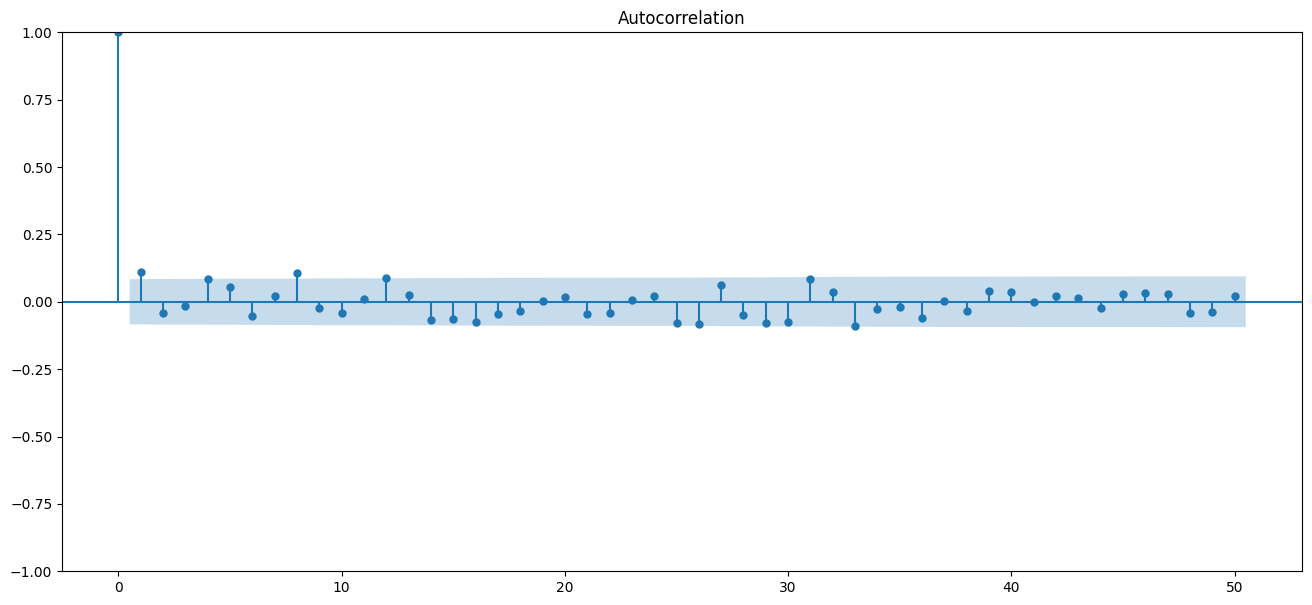

In [12]:
fig, ax = plt.subplots(figsize=(16,7))
plot_acf(yld, lags=50,ax=ax)
plt.show()

Получаем вполне ожидаемую картину для доходностей - доходности соседних периодов вполне могут быть некоррелированы друг с другом, также как и коэффициенты автокорреляции более высоких порядков не являются значительными. 

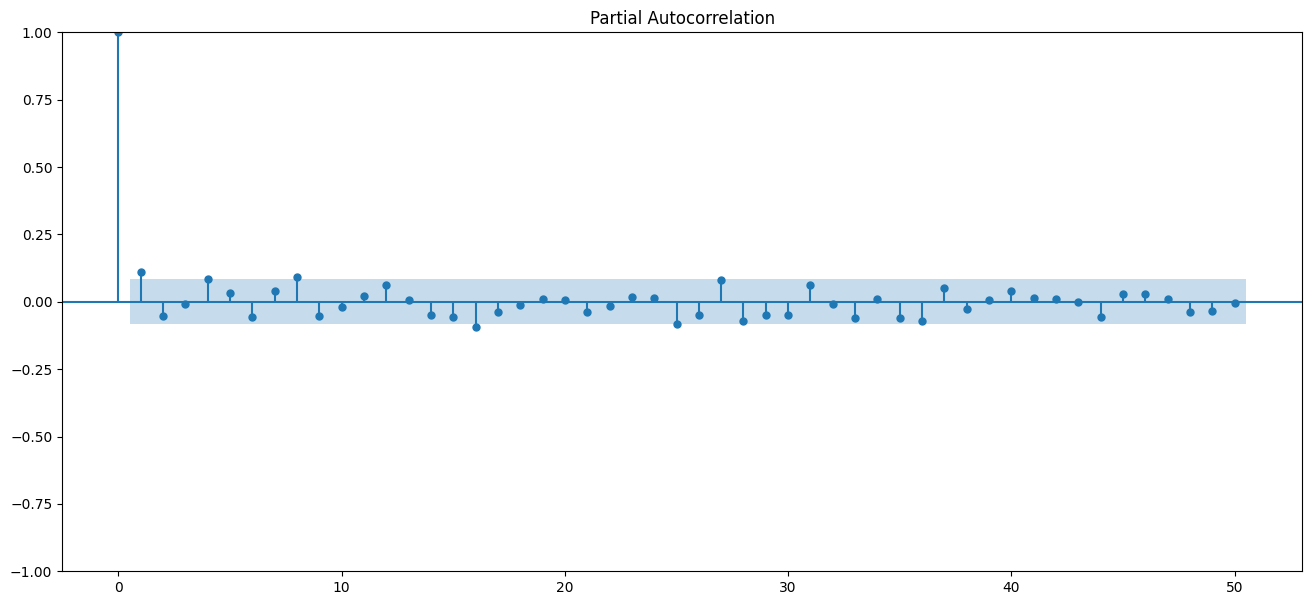

In [13]:
fig, ax = plt.subplots(figsize=(16,7))
plot_pacf(yld, lags=50,ax=ax)
plt.show()

Собственно, PACF показывает всю ту же картину - интересным здесь является только слабое отрицательное влияние шока в период t-2, что, впрочем, скорее всего является статистической погрешностью. В целом, можно говорить об отсутствии зависимости доходности в текущем периоде от исторических значений. Теперь построим график квантиль-квантиль (Q-Q plot) :

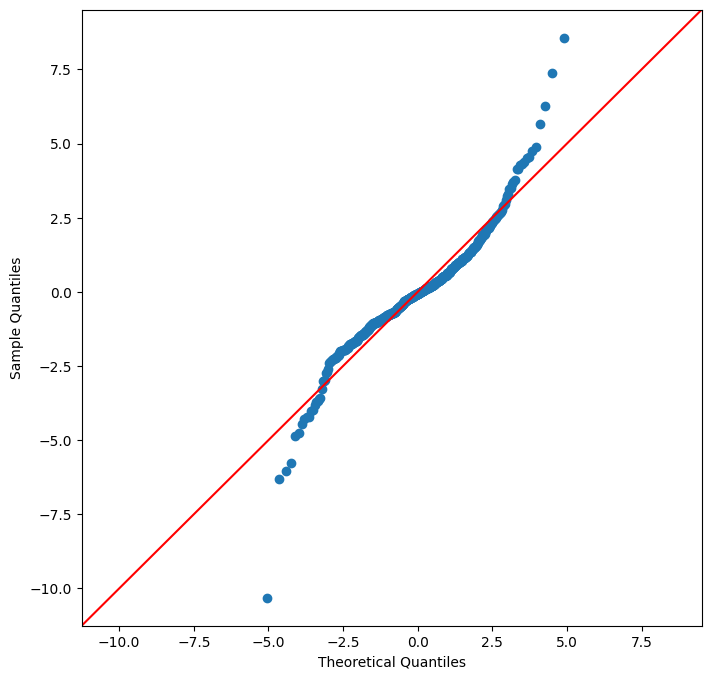

In [14]:
from statsmodels.api import qqplot

fig, ax = plt.subplots(figsize=(8,8))
qqplot(yld, line='45', ax=ax, loc=np.average(yld),scale=(np.var(yld))**(1/2))
plt.show()

Видно, что распределение доходностей имеет более тяжелые хвосты, чем обычное нормальное распределение с такой же дисперсией и мат.ожиданием

Проверим, верны ли наши предположения о том, что наилучшей моделью будет ARIMA(0,0,0) для ВР доходностей

In [15]:
from pmdarima import auto_arima

model = auto_arima(yld, information_criterion='bic', trace=True)

Performing stepwise search to minimize bic
 ARIMA(2,0,2)(0,0,0)[0] intercept   : BIC=2158.487, Time=0.45 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : BIC=2153.672, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : BIC=2153.438, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : BIC=2152.779, Time=0.03 sec
 ARIMA(0,0,0)(0,0,0)[0]             : BIC=2148.302, Time=0.01 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : BIC=2158.709, Time=0.06 sec

Best model:  ARIMA(0,0,0)(0,0,0)[0]          
Total fit time: 0.588 seconds


Собственно, что и требовалось доказать - теперь подберем модель GARCH

In [16]:
from arch import arch_model

results = []

for p in [1, 2]:
    for q in [0, 1, 2]:
        model_grch = arch_model(
            yld,
            mean='constant',
            vol='GARCH',
            p=p,
            q=q,
            dist='normal'
        )
        res = model_grch.fit(disp='off')

        results.append({'p':p, 'q':q, 'AIC':res.aic, 'BIC':res.bic})

table = pd.DataFrame(results)
print(table.sort_values('BIC'))

   p  q          AIC          BIC
1  1  1  1963.161716  1980.386818
4  2  1  1961.943625  1983.475001
2  1  2  1965.161716  1986.693093
5  2  2  1963.943625  1989.781276
3  2  0  2018.329067  2035.554168
0  1  0  2078.349127  2091.267953


Как можно видеть, получили модель GARCH(1,1) при значении BIC = 1682.4, интересным является сравнить модель с нормальным распределением остатков (только что рассмотренную) с моделью со Стьюдентовским распределением остатков

In [17]:
results = []

for p in [1, 2]:
    for q in [0, 1, 2]:
        model_grch = arch_model(
            yld,
            mean='constant',
            vol='GARCH',
            p=p,
            q=q,
            dist='t'
        )
        res = model_grch.fit(disp='off')

        results.append({'p':p, 'q':q, 'AIC':res.aic, 'BIC':res.bic})

table = pd.DataFrame(results)
print(table.sort_values('BIC'))

   p  q          AIC          BIC
1  1  1  1923.147426  1944.678803
4  2  1  1924.324140  1950.161792
2  1  2  1925.147426  1950.985078
5  2  2  1926.278672  1956.422599
3  2  0  1951.067800  1972.599176
0  1  0  1985.972712  2003.197813


Примечательно, что модель с t-распределением остатков лучше, причем наилучшей моделью при t-распределении остатков и по BIC, и по AIC будет GARCH(1,1) с BIC=1644.7. Выведем параметры модели и построим Q-Q график для t-распределения

In [18]:
model_grch = arch_model(yld, mean='constant', vol='GARCH', p=1, q=1, dist='t')
res = model_grch.fit(disp='off')

print(res.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -956.574
Distribution:      Standardized Student's t   AIC:                           1923.15
Method:                  Maximum Likelihood   BIC:                           1944.68
                                              No. Observations:                  548
Date:                      Thu, Dec 25 2025   Df Residuals:                      547
Time:                              22:15:47   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu     

Применение именно t-распределения для стандартизованных остатков оправдано тем, что при сравнении двух идентичных моделей с разницей только в распределениях, модель, использующая t-распределение, имеет меньший BIC

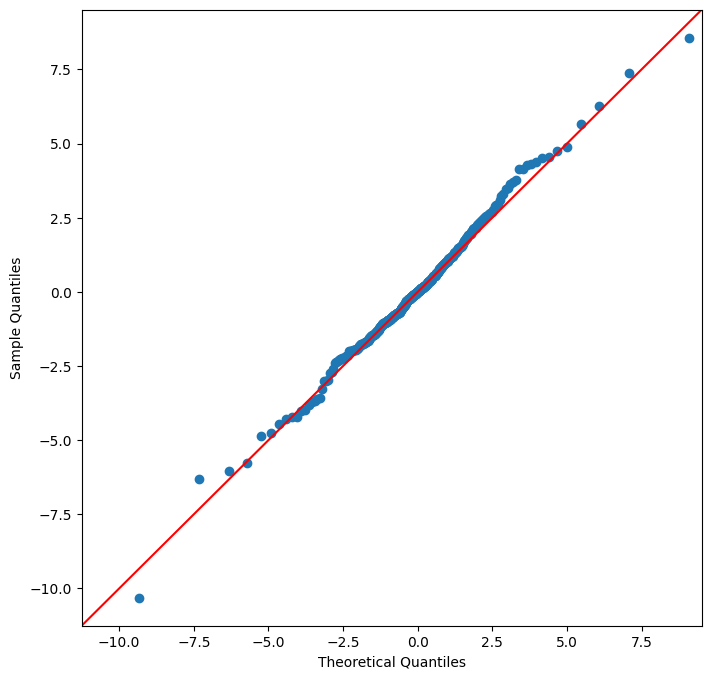

In [19]:
import scipy.stats as stats

df, loc, scale = stats.t.fit(yld)

fig, ax = plt.subplots(figsize=(8,8))
qqplot(yld, dist=stats.t, line='45', ax=ax, loc=loc, scale=scale, distargs=(df,))
plt.show()

Это распределение самого ряда yield - как видно, оно куда как больше похоже на t-распределение. Теперь нам следует сравнить остатки регрессии, полученные при применении GARCH+ модели с теоретическими квантилями (для нормального и t-распределений)

Тут вообще нужно сказать о том, что такое ARCH/GARCH - это такая ситуация, когда дисперсия ошибки периода t зависит от квадрата ошибки (читай, дисперсии) предыдущих периодов $e_t^2 = \alpha * e_{t-1}^2$

Значит, в исходной модели должна была быть такая зависимость (ну раз мы смогли подобрать GARCH-модель) - продемонстрирум это

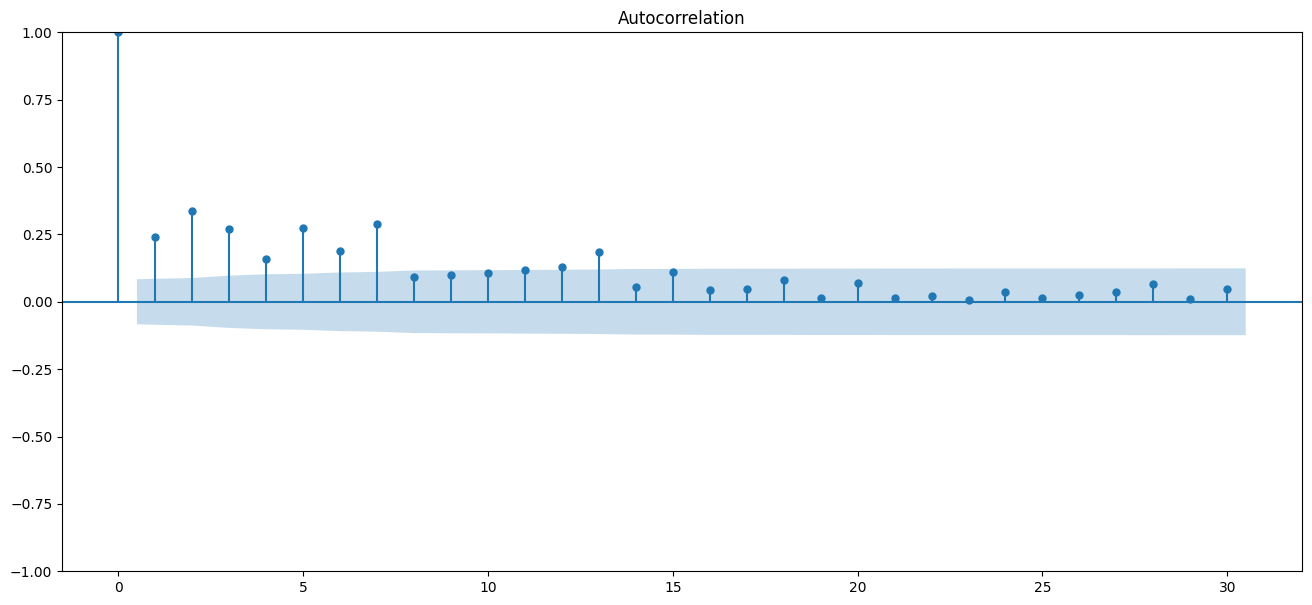

In [20]:
yld_res = (yld - np.average(yld))

fig, ax = plt.subplots(figsize=(16,7))
plot_acf(yld_res**2, ax=ax, lags=30)
plt.show()

Видим, что в ряду доходности акций AFLT наблюдается явная кластеризация волатильностей, а значит - применение модели GARCH на рассматриваемом временном промежутке оправданно. Теперь, когда мы построили GARCH-модель, рассчитаем стандартизованные остатки и убедимся, что они представляют собой белый шум ($z_t = e_t / \sigma _t$)

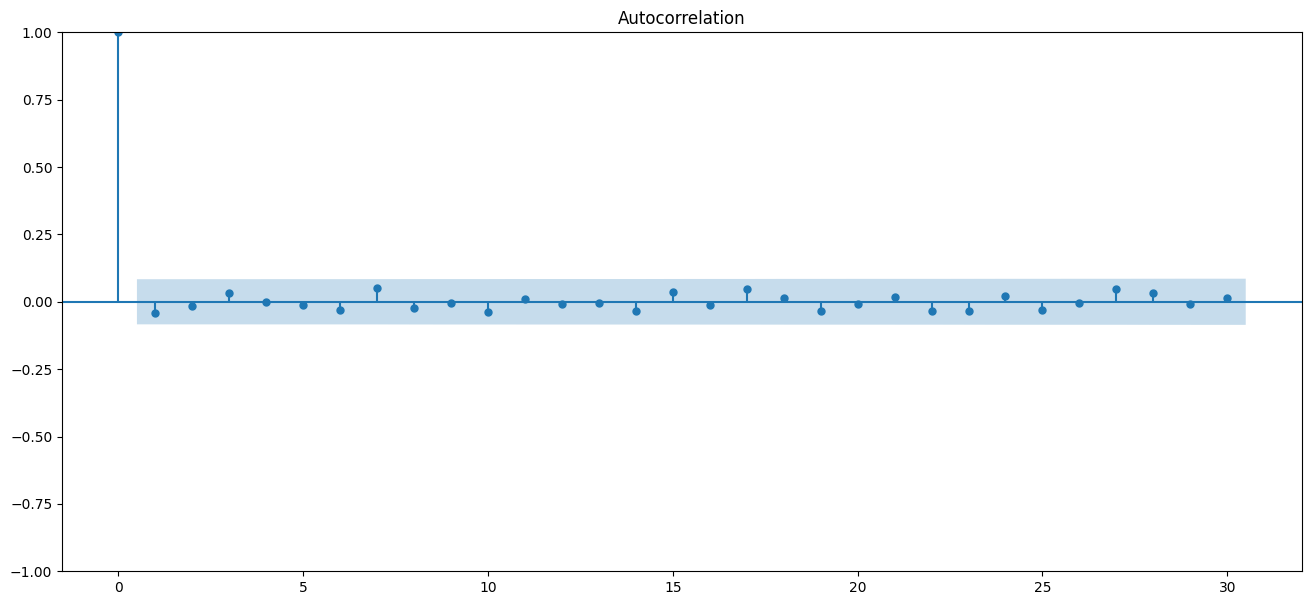

In [21]:
model_grch = arch_model(yld, mean='constant', vol='GARCH', p=1, q=1, dist='t')
res = model_grch.fit(disp='off')

yld_std_res = (res.resid)/(res.conditional_volatility) # Получили что хотели

fig, ax = plt.subplots(figsize=(16,7))
plot_acf(yld_std_res**2, ax=ax, lags=30)
plt.show()

Отлично! Корреляции в стандартизованных остатках нет, значит, все круто - запишем полученную модель

$$
\begin{aligned}
\textbf{Mean equation:} \qquad
y_t &= \mu + \varepsilon_t, 
& \mu &= -0.0862 \; (0.0345) \\[6pt]

\textbf{Error decomposition:} \qquad
\varepsilon_t &= \sigma_t z_t,
& z_t &\sim t_{\nu}(0,1), 
& \nu &= 5.0120 \; (0.988) \\[8pt]

\textbf{Volatility equation (GARCH(1,1)):} \qquad
\sigma_t^2 &= \omega 
+ \alpha_1 \varepsilon_{t-1}^2 
+ \beta_1 \sigma_{t-1}^2, \\[4pt]
& \omega = 0.0439 \; (0.0258), \\[-2pt]
& \alpha_1 = 0.1661 \; (0.0541), \\[-2pt]
& \beta_1 = 0.8195 \; (0.0556)
\end{aligned}
$$

Теперь построим прогноз на 5 наблюдений вперед

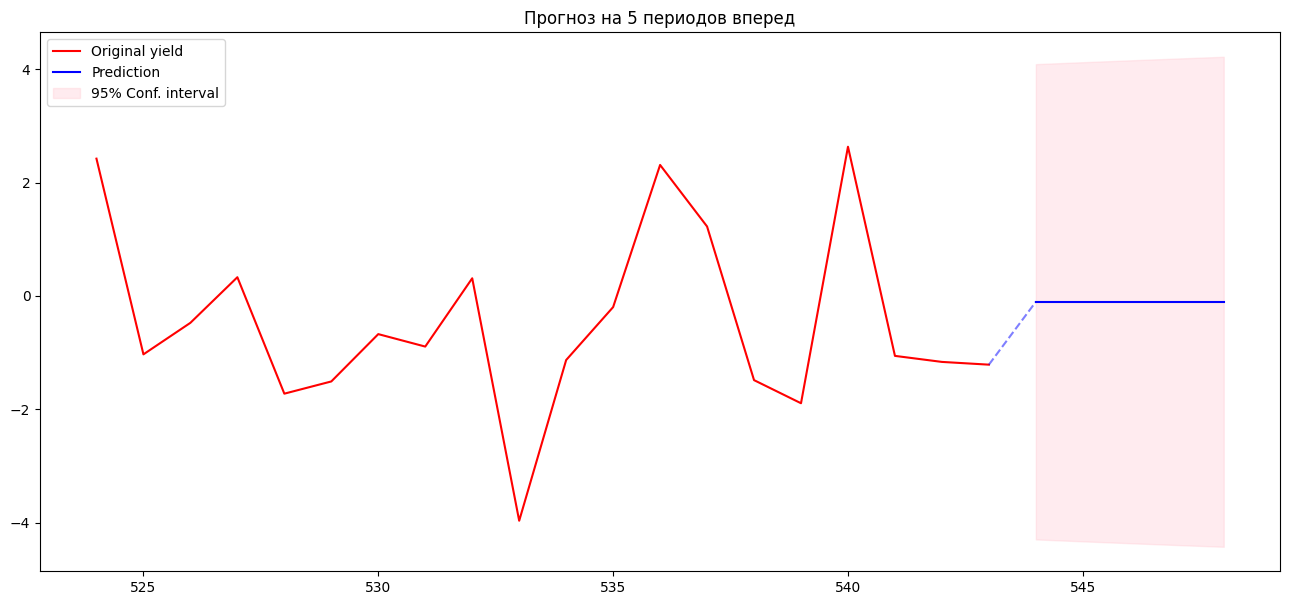

In [22]:
model_grch = arch_model(yld[:(len(yld)-5)], mean='constant', vol='GARCH', p=1, q=1, dist='t')
res = model_grch.fit(disp='off')

forecast = res.forecast(horizon=5, reindex=False)

trend = forecast.mean.values
st_err = np.sqrt(forecast.variance.values)
quant = stats.t.ppf(0.975, df=res.params['nu']) # Квантиль t-распределения, т.к. считаем что так распределены ст. остатки

lbound = trend - quant*st_err # Нижняя грань
ubound = trend + quant*st_err # Верхняя грань
for_graph = [float(yld[len(yld)-6]), float(trend[0][0])]


plt.figure(figsize=(16,7))
plt.plot(range(len(yld)-24, len(yld)-4), yld[(len(yld)-25):len(yld)-5], label='Original yield', color='red')
plt.plot(range(len(yld)-4,len(yld)+1),trend[0], color='blue', label='Prediction')
plt.fill_between(range(len(yld)-4, len(yld)+1), lbound[0], ubound[0], color='pink', alpha=0.3, label='95% Conf. interval')
plt.plot(range(len(yld)-5, len(yld)-3), for_graph, color='blue', alpha=0.5, linestyle='--')
plt.title('Прогноз на 5 периодов вперед')
plt.legend()
plt.show()

Теперь сравним полученный прогноз с реальными данными

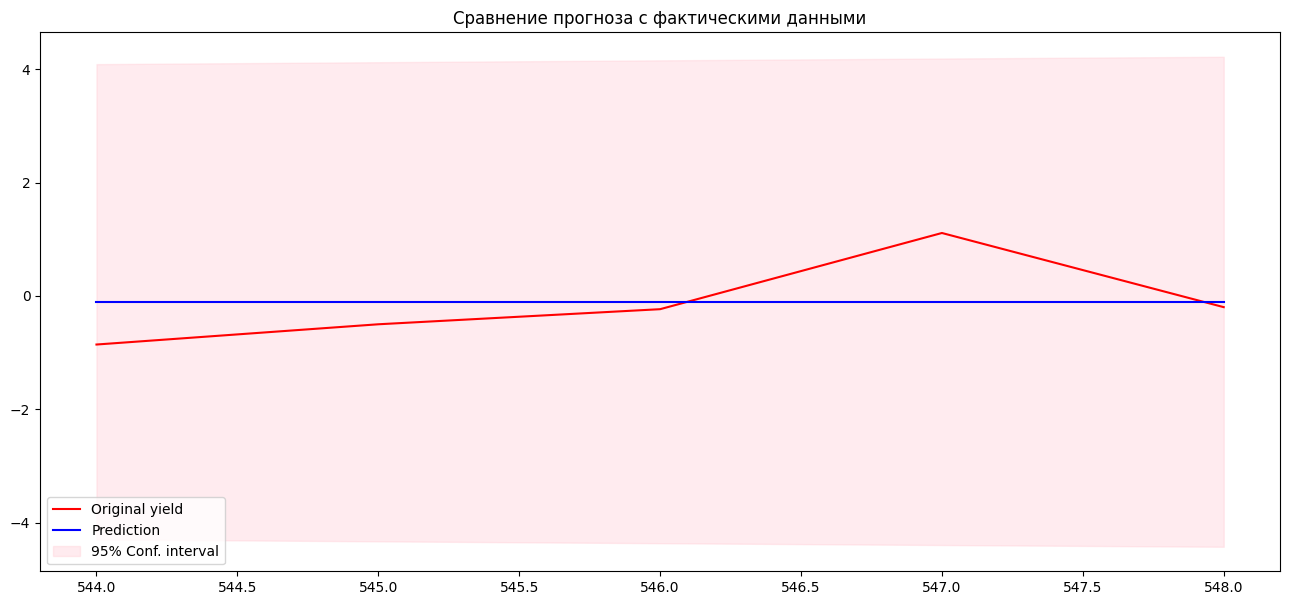

In [23]:
plt.figure(figsize=(16,7))
plt.plot(range(len(yld)-4, len(yld)+1), yld[(len(yld)-5):], label='Original yield', color='red')
plt.plot(range(len(yld)-4,len(yld)+1),trend[0], color='blue', label='Prediction')
plt.fill_between(range(len(yld)-4, len(yld)+1), lbound[0], ubound[0], color='pink', alpha=0.3, label='95% Conf. interval')

plt.title('Сравнение прогноза с фактическими данными')
plt.legend()
plt.show()

Как можно видеть, прогноз достаточно неплохо совпадает с фактом, что конечно не заслуга прогноза, поскольку это просто среднее - приведем формальные критерии (MAE, MSE, MAPE) в поддержку наших слов:

In [24]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

actuals = yld[len(yld)-5:]


mse = mean_squared_error(actuals, trend[0])
mae = mean_absolute_error(actuals, trend[0])
mape = mean_absolute_percentage_error(actuals, trend[0])

print(f'MSE : {mse}')
print(f'MAE : {mae}')
print(f'MAPE : {mape}')

MSE : 0.445238641364435
MAE : 0.5181743685227039
MAPE : 0.7590586503509993


Посмотрим, как изменялась условная дисперсия, а вместе с ней - 95% доверительные интервалы

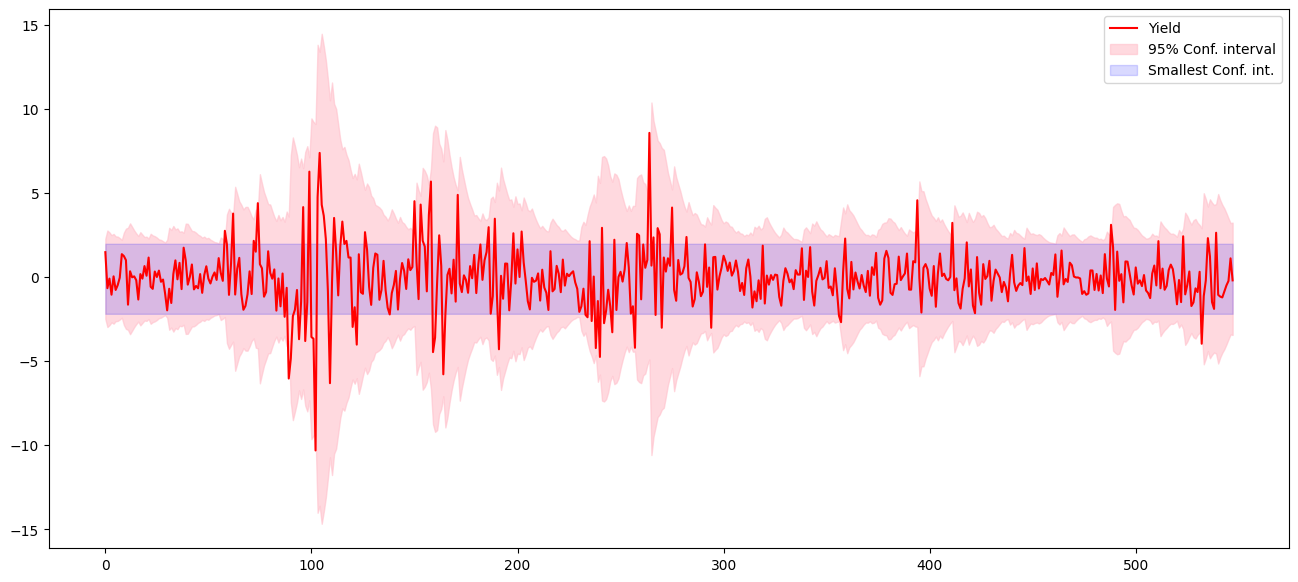

In [25]:
model_grch = arch_model(yld, mean='constant', vol='GARCH', p=1, q=1, dist='t')
res = model_grch.fit(disp='off')

mu = res.params['mu']
nu = res.params['nu']
q = stats.t.ppf(0.975, df=nu)

sigma_t = res.conditional_volatility
min_disp_l = [mu - min(sigma_t)*(q) for i in range(len(yld))]
min_disp_u = [mu + min(sigma_t)*q for i in range(len(yld))]
max_disp_l = [mu - max(sigma_t)*(q) for i in range(len(yld))]
max_disp_u = [mu + min(sigma_t)*q for i in range(len(yld))]

lower = mu - q*sigma_t
upper = mu + q*sigma_t

plt.figure(figsize=(16,7))
plt.plot(yld, label='Yield', color='red')
plt.fill_between(range(len(yld)), lower, upper, color='pink', alpha=0.6, label='95% Conf. interval')
# plt.plot(min_disp_l, color='blue', alpha=0.35, linestyle='--')
# plt.plot(min_disp_u, color='blue', alpha=0.35, linestyle='--')

plt.fill_between(range(len(yld)), min_disp_l, min_disp_u, color='blue', alpha=0.15, label='Smallest Conf. int.')
# plt.fill_between(range(len(yld)), max_disp_l, max_disp_u, color='red', alpha=0.1, label='Biggest Conf. int.')

plt.legend()
plt.show()

Построим график VaR и проведем тест Купика

Нарушений: 1 из 48 (0.021)
Kupiec: 1.092, crit: 3.841


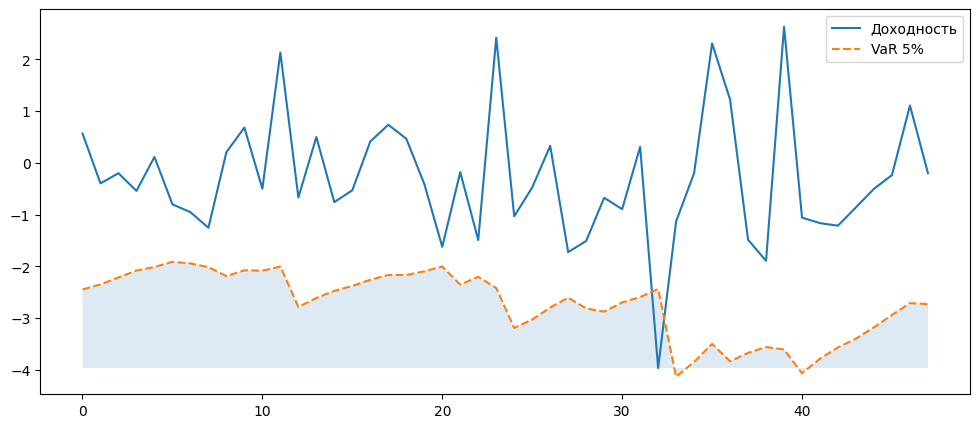

VaR проходит тест Купика


In [ ]:
risk = 0.05
window = 500   # размер обучающего окна

VaR = []
y_real = []

for t in range(window, len(yld)):
    train = yld[:t]

    model = arch_model(
        train,
        mean='constant',
        vol='GARCH',
        p=1, q=1,
        dist='t'
    )
    res = model.fit(disp='off')

    mu = res.params['mu']
    nu = res.params['nu']

    # прогноз условной дисперсии на 1 шаг вперёд
    sigma_next = np.sqrt(
        res.forecast(horizon=1).variance.values[-1, 0]
    )

    VaR.append(mu + sigma_next * stats.t.ppf(risk, nu))
    y_real.append(yld[t])

VaR = np.array(VaR)
y_real = np.array(y_real)

viol = (y_real < VaR).astype(int)
x = viol.sum()
N = len(viol)

p_hat = x / N
KupStat = -2 * np.log(((1-risk)**(N-x) * risk**x) / ((1-p_hat)**(N-x) * p_hat**x))

crit = stats.chi2.ppf(0.95, 1)

print(f'Нарушений: {x} из {N} ({p_hat:.3f})')
print(f'Kupiec: {KupStat:.3f}, crit: {crit:.3f}')

plt.figure(figsize=(12,5))
plt.plot(y_real, label='Доходность')
plt.plot(VaR, '--', label='VaR 5%')
plt.fill_between(range(len(VaR)), VaR, y_real.min(), alpha=0.15)
plt.legend()
plt.show()

if KupStat < crit:
    print('VaR адекватно')
else:
    print('VaR адекватно')